# Reproducing CS-Flow on MVTec AD – one class per run

**Paper:** *Fully Convolutional Cross-Scale-Flows for Image-based Defect Detection*, Rudolph, Wehrbein, Rosenhahn, Wandt (WACV 2022)

https://github.com/marco-rudolph/cs-flow


---
## Packages and GPU


In [2]:
#   Check packages and GPU

import importlib, sys

required = {'torch': 'torch', 'torchvision': 'torchvision', 'efficientnet_pytorch': 'efficientnet-pytorch',
            'sklearn': 'scikit-learn', 'scipy': 'scipy', 'matplotlib': 'matplotlib', 'tqdm': 'tqdm',
            'numpy': 'numpy', 'PIL': 'pillow'}
missing = []
for module, pip_name in required.items():
    try:
        m = importlib.import_module(module)
        print(f'  OK  {pip_name:22s} {getattr(m, "__version__", "")}')
    except ImportError:
        missing.append(pip_name)
        print(f'  --  {pip_name:22s} MISSING')
if missing:
    raise ImportError('Missing packages: ' + ', '.join(missing) + '  -> install them with cell 0.1, then restart the kernel.')

import torch
print('\nPython :', sys.version.split()[0])
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU    : {props.name}, {props.total_memory / 1024**3:.1f} GB  -> training runs on the GPU')
else:
    print('GPU    : NOT FOUND -> everything runs on the CPU.')

  OK  torch                  2.11.0+cu128
  OK  torchvision            0.26.0+cu128
  OK  efficientnet-pytorch   0.7.1
  OK  scikit-learn           1.7.1
  OK  scipy                  1.18.1
  OK  matplotlib             3.9.3
  OK  tqdm                   4.68.4
  OK  numpy                  2.5.4
  OK  pillow                 12.3.0

Python : 3.12.8
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU, 8.0 GB  -> training runs on the GPU


---
## 1. Imports
All imports of all repository files, in one place.

In [3]:
# 1.1  Imports (standard library, PyTorch, plotting, metrics)

import os, re, json, time, shutil, random, warnings
from pathlib import Path
from math import exp
from copy import deepcopy
from os.path import join
from types import SimpleNamespace

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import Dataset
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder
from efficientnet_pytorch import EfficientNet
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tqdm import tqdm
import matplotlib.pyplot as plt
import PIL.Image
from IPython.display import Image, display, Markdown

PROJECT_DIR = Path.cwd()   # features, models, figures and results are stored here
os.chdir(PROJECT_DIR)      # the repository code uses paths relative to this folder
print('Project folder:', PROJECT_DIR)

Project folder: D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\MVTech Notebook Implementation


---
## 2. Configuration (`config.py`)


In [4]:
# config.py  -  all settings for CS-Flow (data, model, training) in one object `c`

c = SimpleNamespace()

# Device settings
c.device = 'cuda' if torch.cuda.is_available() else 'cpu'  

# Data settings  
c.dataset_path = 'MVTech dataset'  # parent directory of datasets
c.class_name = 'bottle'  # dataset subdirectory
c.modelname = 'mvtec_bottle'  # export evaluations/logs with this name
c.pre_extracted = True  # were feature preextracted with extract_features?

c.img_size = (768, 768)  # image size of highest scale (MVTec AD: 768x768)


# Transformation settings (ImageNet normalisation - EfficientNet was trained on ImageNet)
c.norm_mean, c.norm_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Network hyperparameters 
c.n_scales = 3  # number of scales at which features are extracted
c.clamp = 3  # clamping parameter (alpha in paper Eq. 4)
c.max_grad_norm = 1e0  # clamp gradients to this norm
c.n_coupling_blocks = 4  # higher = more flexible = more unstable
c.fc_internal = 1024  # * 4 # number of neurons in hidden layers of s-t-networks
c.lr_init = 2e-4  # inital learning rate
c.use_gamma = True  # learnable gamma scaling inside the subnetworks
c.extractor = "effnetB5"  # feature dataset name

# Dataloader parameters 
c.batch_size = 16

c.meta_epochs = 4  # total epochs = meta_epochs * sub_epochs
c.sub_epochs = 60  # evaluate after this number of epochs

# Output settings
c.verbose = True
c.hide_tqdm_bar = True
c.save_model = True  # save the trained model

# Values derived from the settings above 
def update_derived():
    assert c.img_size[0] % 128 == 0 and c.img_size[1] % 128 == 0, "image width/height should be a multiple of 128"
    c.img_dims = [3] + list(c.img_size)
    c.n_feat = {"effnetB5": 304}[c.extractor]  # dependend from feature extractor
    c.map_size = (c.img_size[0] // 32, c.img_size[1] // 32)  # spatial size of the largest feature map
    c.kernel_sizes = [3] * (c.n_coupling_blocks - 1) + [5]  # last coupling block uses 5x5 kernels


def set_config(**settings):
    for name, value in settings.items():
        if not hasattr(c, name):
            raise KeyError(f'unknown setting: {name}')
        setattr(c, name, value)
    update_derived()
    print('config:', ', '.join(f'{k}={v!r}' for k, v in settings.items()))


def show_config():
    keys = ['device', 'dataset_path', 'class_name', 'modelname', 'img_size', 'map_size', 'batch_size', 'meta_epochs', 'sub_epochs']
    print(' | '.join(f'{k}={getattr(c, k)!r}' for k in keys) + f'  -> {c.meta_epochs * c.sub_epochs} epochs')


update_derived()

---
## 3. The repository's code (one cell per file)



### 3.1 `utils.py`

In [5]:
# utils.py  -  loss, datasets and helpers
import os
import torch
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset
import numpy as np

# Free memory between runs.
import gc

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Tensor helpers
def t2np(tensor):
    '''pytorch tensor -> numpy array'''
    return tensor.cpu().data.numpy() if tensor is not None else None


def flat(tensor):
    return tensor.reshape(tensor.shape[0], -1)


def concat_maps(maps):
    # flattens the 3 output maps (one per scale) and joins them into one vector per sample
    flat_maps = list()
    for m in maps:
        flat_maps.append(flat(m))
    return torch.cat(flat_maps, dim=1)[..., None]


# Loss: negative log-likelihood of a standard normal latent space, minus the
# log-Jacobian determinant, normalised by the number of dimensions (paper Eq. 6)
def get_loss(z, jac):
    z = torch.cat([z[i].reshape(z[i].shape[0], -1) for i in range(len(z))], dim=1)
    jac = sum(jac)
    return torch.mean(0.5 * torch.sum(z ** 2, dim=(1,)) - jac) / z.shape[1]


def cat_maps(z):
    return torch.cat([z[i].reshape(z[i].shape[0], -1) for i in range(len(z))], dim=1)


# Dataset loading
def load_datasets(dataset_path, class_name):
    '''
    Expected folder/file format to find anomalies of class <class_name> from dataset location <dataset_path>:

    train data:

            dataset_path/class_name/train/good/any_filename.png
            dataset_path/class_name/train/good/another_filename.tif
            dataset_path/class_name/train/good/xyz.png
            [...]

    test data:

        'normal data' = non-anomalies

            dataset_path/class_name/test/good/name_the_file_as_you_like_as_long_as_there_is_an_image_extension.webp
            dataset_path/class_name/test/good/did_you_know_the_image_extension_webp?.png
            dataset_path/class_name/test/good/did_you_know_that_filenames_may_contain_question_marks????.png
            dataset_path/class_name/test/good/dont_know_how_it_is_with_windows.png
            dataset_path/class_name/test/good/just_dont_use_windows_for_this.png
            [...]

        anomalies - assume there are anomaly classes 'crack' and 'curved'

            dataset_path/class_name/test/crack/dat_crack_damn.png
            dataset_path/class_name/test/crack/let_it_crack.png
            dataset_path/class_name/test/crack/writing_docs_is_fun.png
            [...]

            dataset_path/class_name/test/curved/wont_make_a_difference_if_you_put_all_anomalies_in_one_class.png
            dataset_path/class_name/test/curved/but_this_code_is_practicable_for_the_mvtec_dataset.png
            [...]
    '''

    def target_transform(target):
        return class_perm[target]

    if c.pre_extracted:
        trainset = FeatureDataset(train=True)
        testset = FeatureDataset(train=False)
    else:
        data_dir_train = os.path.join(dataset_path, class_name, 'train')
        data_dir_test = os.path.join(dataset_path, class_name, 'test')

        classes = os.listdir(data_dir_test)
        if 'good' not in classes:
            raise FileNotFoundError('There should exist a subdirectory "good". Read the doc of this function for further information.')
        classes.sort()
        class_perm = list()
        class_idx = 1
        for cl in classes:
            if cl == 'good':
                class_perm.append(0)
            else:
                class_perm.append(class_idx)
                class_idx += 1

        # resize -> tensor -> ImageNet normalisation (grayscale images, e.g. MVTec grid/screw/zipper, are converted to RGB by ImageFolder)
        tfs = [transforms.Resize(c.img_size), transforms.ToTensor(), transforms.Normalize(c.norm_mean, c.norm_std)]
        transform_train = transforms.Compose(tfs)

        trainset = ImageFolder(data_dir_train, transform=transform_train)
        testset = ImageFolder(data_dir_test, transform=transform_train, target_transform=target_transform)
    return trainset, testset


class FeatureDataset(Dataset):
    '''Serves the cached features written by extract_features.py:
    data/features/<class_name>/<class_name>_scale_<s>_<train|test>.npy'''

    def __init__(self, root=None, n_scales=None, train=False):
        if root is None:
            root = "data/features/" + c.class_name + '/'
        if n_scales is None:
            n_scales = c.n_scales

        super(FeatureDataset, self).__init__()
        self.data = list()
        self.n_scales = n_scales
        self.train = train
        suffix = 'train' if train else 'test'

        for s in range(c.n_scales):
            self.data.append(np.load(root + c.class_name + '_scale_' + str(s) + '_' + suffix + '.npy'))

        self.labels = np.load(os.path.join(root, c.class_name + '_labels.npy')) if not train else np.zeros(
            [len(self.data[0])])
        self.paths = np.load(os.path.join(root, c.class_name + '_image_paths.npy'))
        self.class_names = [os.path.basename(os.path.dirname(str(img_path))) for img_path in self.paths]

    def __len__(self):
        return len(self.data[0])

    def __getitem__(self, index):
        out = list()
        for d in self.data:
            sample = d[index]
            sample = torch.FloatTensor(sample)
            out.append(sample)
        return out, self.labels[index]


def make_dataloaders(trainset, testset):
    trainloader = torch.utils.data.DataLoader(trainset, pin_memory=True, batch_size=c.batch_size, shuffle=True,
                                              drop_last=False)
    testloader = torch.utils.data.DataLoader(testset, pin_memory=True, batch_size=c.batch_size, shuffle=False,
                                             drop_last=False)
    return trainloader, testloader


# Move a batch to the GPU/CPU (features come as a list of 3 tensors, one per scale)
def preprocess_batch(data):
    '''move data to device and reshape image'''
    if c.pre_extracted:
        inputs, labels = data
        for i in range(len(inputs)):
            inputs[i] = inputs[i].to(c.device)
        labels = labels.to(c.device)
    else:
        inputs, labels = data
        inputs, labels = inputs.to(c.device), labels.to(c.device)
        inputs = inputs.view(-1, *inputs.shape[-3:])
    return inputs, labels


# Keeps track of the latest and best test score. 
class Score_Observer:
    '''Keeps an eye on the current and highest score so far'''

    def __init__(self, name):
        self.name = name
        self.max_epoch = 0
        self.max_score = None
        self.min_loss_epoch = 0
        self.min_loss_score = 0
        self.min_loss = None
        self.last = None

    def update(self, score, epoch, print_score=False):
        self.last = score
        if self.max_score == None or score > self.max_score:
            self.max_score = score
            self.max_epoch = epoch
        if print_score:
            self.print_score()

    def print_score(self):
        print('{:s}: \t last: {:.4f} \t max: {:.4f} \t epoch_max: {:d} \t epoch_loss: {:d}'.format(self.name, self.last,
                                                                                                   self.max_score,
                                                                                                   self.max_epoch,
                                                                                                   self.min_loss_epoch))

### 3.2 `freia_funcs.py`
* `CrossConvolutions`: the cross-scale subnetwork (paper **Fig. 4**).
* `parallel_glow_coupling_layer`: affine coupling block (paper **Eq. 3**) with the soft clamp (paper **Eq. 4**).
* The rest is generic graph code from the FrEIA framework.

In [6]:
# freia_funcs.py  -  normalizing-flow building blocks (from the FrEIA framework)

'''This Code is based on the FrEIA Framework, source: https://github.com/VLL-HD/FrEIA
It is a assembly of the necessary modules/functions from FrEIA that are needed for our purposes.'''
import torch
import torch.nn as nn
from torch.autograd import Variable
from math import exp
import numpy as np

VERBOSE = False

# Placeholder that only carries the input shape of an InputNode
class dummy_data:
    def __init__(self, *dims):
        self.dims = dims

    @property
    def shape(self):
        return self.dims


# Cross-scale subnetwork (paper Fig. 4): per-scale 3x3 convs, plus up-/down-sampling
# convs that pass information between neighbouring scales. Outputs s and t for
# the affine transform; scaled by learnable gammas (initialised to 0).
class CrossConvolutions(nn.Module):
    '''ResNet transformation, not itself reversible, just used below'''

    def __init__(self, in_channels, channels, channels_hidden=512,
                 stride=None, kernel_size=3, last_kernel_size=1, leaky_slope=0.1,
                 batch_norm=False, block_no=0):
        super(CrossConvolutions, self).__init__()
        if stride:
            warnings.warn("Stride doesn't do anything, the argument should be "
                          "removed", DeprecationWarning)
        if not channels_hidden:
            channels_hidden = channels

        pad = kernel_size // 2
        self.leaky_slope = leaky_slope
        pad_mode = 'zeros'

        self.gamma0 = nn.Parameter(torch.zeros(1))
        self.gamma1 = nn.Parameter(torch.zeros(1))
        self.gamma2 = nn.Parameter(torch.zeros(1))

        # Per-scale convolutions
        self.conv_scale0_0 = nn.Conv2d(in_channels, channels_hidden,
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)

        self.conv_scale1_0 = nn.Conv2d(in_channels, channels_hidden,
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)
        self.conv_scale2_0 = nn.Conv2d(in_channels, channels_hidden,
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)
        self.conv_scale0_1 = nn.Conv2d(channels_hidden * 1, channels,  #
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode, dilation=1)
        self.conv_scale1_1 = nn.Conv2d(channels_hidden * 1, channels,  #
                                       kernel_size=kernel_size, padding=pad * 1,
                                       bias=not batch_norm, padding_mode=pad_mode, dilation=1)
        self.conv_scale2_1 = nn.Conv2d(channels_hidden * 1, channels,  #
                                       kernel_size=kernel_size, padding=pad,
                                       bias=not batch_norm, padding_mode=pad_mode)

        # Cross-scale convolutions: the connections between scales
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)

        # upsample 12×12 → 24×24, then conv 1024 → 304
        self.up_conv10 = nn.Conv2d(channels_hidden, channels,
                                   kernel_size=kernel_size, padding=pad, bias=True, padding_mode=pad_mode)

        
        self.up_conv21 = nn.Conv2d(channels_hidden, channels,
                                   kernel_size=kernel_size, padding=pad, bias=True, padding_mode=pad_mode)

        self.down_conv01 = nn.Conv2d(channels_hidden, channels,
                                     kernel_size=kernel_size, padding=pad,
                                     bias=not batch_norm, stride=2, padding_mode=pad_mode, dilation=1)

        self.down_conv12 = nn.Conv2d(channels_hidden, channels,
                                     kernel_size=kernel_size, padding=pad,
                                     bias=not batch_norm, stride=2, padding_mode=pad_mode, dilation=1)

        self.lr = nn.LeakyReLU(self.leaky_slope)

    def forward(self, x0, x1, x2):
        out0 = self.conv_scale0_0(x0)
        out1 = self.conv_scale1_0(x1)
        out2 = self.conv_scale2_0(x2)

        y0 = self.lr(out0)
        y1 = self.lr(out1)
        y2 = self.lr(out2)

        out0 = self.conv_scale0_1(y0)
        out1 = self.conv_scale1_1(y1)
        out2 = self.conv_scale2_1(y2)

        y1_up = self.up_conv10(self.upsample(y1))
        y2_up = self.up_conv21(self.upsample(y2))

        y0_down = self.down_conv01(y0)
        y1_down = self.down_conv12(y1)

        out0 = out0 + y1_up
        out1 = out1 + y0_down + y2_up
        out2 = out2 + y1_down

        if c.use_gamma:
            out0 = out0 * self.gamma0
            out1 = out1 * self.gamma1
            out2 = out2 * self.gamma2
        return out0, out1, out2

# Fixed random channel permutation (one per scale), applied before each coupling 
# Shuffles the channel order in a randow but fixed way. Every coupling block splits the 304 channels the same way. 
# Therefore, Without shuffling, the same channels would always be grouped together, in all 4 blocks.
class ParallelPermute(nn.Module):
    '''permutes input vector in a random but fixed way'''

    def __init__(self, dims_in, seed):
        super(ParallelPermute, self).__init__()
        # print('dims in', dims_in)
        # exit()
        self.n_inputs = len(dims_in)
        self.in_channels = [dims_in[i][0] for i in range(self.n_inputs)]

        np.random.seed(seed)
        perm, perm_inv = self.get_random_perm(0)
        self.perm = [perm]
        self.perm_inv = [perm_inv]

        for i in range(1, self.n_inputs):
            perm, perm_inv = self.get_random_perm(i)
            self.perm.append(perm)
            self.perm_inv.append(perm_inv)

    def get_random_perm(self, i):
        perm = np.random.permutation(self.in_channels[i])
        perm_inv = np.zeros_like(perm)
        for i, p in enumerate(perm):
            perm_inv[p] = i

        perm = torch.LongTensor(perm)
        perm_inv = torch.LongTensor(perm_inv)
        return perm, perm_inv

    # Apply the suffel
    def forward(self, x, rev=False):
        if not rev:
            return [x[i][:, self.perm[i]] for i in range(self.n_inputs)]
        else:
            return [x[i][:, self.perm_inv[i]] for i in range(self.n_inputs)]

    def jacobian(self, x, rev=False):
        # TODO: use batch size, set as nn.Parameter so cuda() works
        return [0.] * self.n_inputs   # Always zero

    # Suffling does not change the shape
    def output_dims(self, input_dims):
        return input_dims

# Affine coupling block (paper Eq. 3): split channels in two halves, transform one
# half with scale e(s) and shift t predicted from the other half, then swap roles.
# The log-Jacobian of each scale is stored in self.last_jac.
class parallel_glow_coupling_layer(nn.Module):
    def __init__(self, dims_in, F_class=CrossConvolutions, F_args={},
                 clamp=5.):
        super(parallel_glow_coupling_layer, self).__init__()
        channels = dims_in[0][0]
        self.ndims = len(dims_in[0])

        # Spilt the channels into half (304 -> 152)
        self.split_len1 = channels // 2
        self.split_len2 = channels - channels // 2

        # Clamping value for the scaling parameter
        self.clamp = clamp

        self.max_s = exp(clamp)
        self.min_s = exp(-clamp)

        # Define cross convolutional subnetwork for each half
        self.s1 = F_class(self.split_len1, self.split_len2 * 2, **F_args)
        self.s2 = F_class(self.split_len2, self.split_len1 * 2, **F_args)

    # Exponentionl scaling value
    def e(self, s):
        if self.clamp > 0:
            return torch.exp(self.log_e(s))
        else:
            return torch.exp(s)

    def log_e(self, s):
        if self.clamp > 0:
            return self.clamp * 0.636 * torch.atan(s / self.clamp)
        else:
            return s

    def forward(self, x, rev=False):
        # Spilt to half in all 3 scales
        x01, x02 = (x[0].narrow(1, 0, self.split_len1),
                    x[0].narrow(1, self.split_len1, self.split_len2))
        x11, x12 = (x[1].narrow(1, 0, self.split_len1),
                    x[1].narrow(1, self.split_len1, self.split_len2))
        x21, x22 = (x[2].narrow(1, 0, self.split_len1),
                    x[2].narrow(1, self.split_len1, self.split_len2))

        if not rev:
            r02, r12, r22 = self.s2(x02, x12, x22)

            # Get the scaling and shifting parameters
            # 1st half of r is s and the remaining half is t (r (304) -> [s (152), t(152)])
            s02, t02 = r02[:, :self.split_len1], r02[:, self.split_len1:]
            s12, t12 = r12[:, :self.split_len1], r12[:, self.split_len1:]
            s22, t22 = r22[:, :self.split_len1], r22[:, self.split_len1:]

            y01 = self.e(s02) * x01 + t02
            y11 = self.e(s12) * x11 + t12
            y21 = self.e(s22) * x21 + t22

            r01, r11, r21 = self.s1(y01, y11, y21)

            s01, t01 = r01[:, :self.split_len2], r01[:, self.split_len2:]
            s11, t11 = r11[:, :self.split_len2], r11[:, self.split_len2:]
            s21, t21 = r21[:, :self.split_len2], r21[:, self.split_len2:]
            y02 = self.e(s01) * x02 + t01
            y12 = self.e(s11) * x12 + t11
            y22 = self.e(s21) * x22 + t21

        else:  # names of x and y are swapped!
            # to map latent values back to features
            
            r01, r11, r21 = self.s1(x01, x11, x21)

            s01, t01 = r01[:, :self.split_len2], r01[:, self.split_len2:]
            s11, t11 = r11[:, :self.split_len2], r11[:, self.split_len2:]
            s21, t21 = r21[:, :self.split_len2], r21[:, self.split_len2:]

            y02 = (x02 - t01) / self.e(s01)
            y12 = (x12 - t11) / self.e(s11)
            y22 = (x22 - t21) / self.e(s21)

            r02, r12, r22 = self.s2(y02, y12, y22)

            s02, t02 = r02[:, :self.split_len2], r01[:, self.split_len2:]
            s12, t12 = r12[:, :self.split_len2], r11[:, self.split_len2:]
            s22, t22 = r22[:, :self.split_len2], r21[:, self.split_len2:]

            y01 = (x01 - t02) / self.e(s02)
            y11 = (x11 - t12) / self.e(s12)
            y21 = (x21 - t22) / self.e(s22)

        # Concatanate the 2 halves for each scale
        y0 = torch.cat((y01, y02), 1)
        y1 = torch.cat((y11, y12), 1)
        y2 = torch.cat((y21, y22), 1)

        y0 = torch.clamp(y0, -1e6, 1e6)
        y1 = torch.clamp(y1, -1e6, 1e6)
        y2 = torch.clamp(y2, -1e6, 1e6)

        # Compute the jacobian
        jac0 = torch.sum(self.log_e(s01), dim=(1, 2, 3)) + torch.sum(self.log_e(s02), dim=(1, 2, 3))
        jac1 = torch.sum(self.log_e(s11), dim=(1, 2, 3)) + torch.sum(self.log_e(s12), dim=(1, 2, 3))
        jac2 = torch.sum(self.log_e(s21), dim=(1, 2, 3)) + torch.sum(self.log_e(s22), dim=(1, 2, 3))
        self.last_jac = [jac0, jac1, jac2]

        return [y0, y1, y2]

    # Output the jacobian
    def jacobian(self, x, rev=False):
        return self.last_jac

    def output_dims(self, input_dims):
        return input_dims


# Graph machinery (generic FrEIA code): nodes, inputs, outputs and the network
class Node:
    '''The Node class represents one transformation in the graph, with an
    arbitrary number of in- and outputs.'''

    def __init__(self, inputs, module_type, module_args, name=None):
        self.inputs = inputs
        self.outputs = []
        self.module_type = module_type
        self.module_args = module_args

        self.input_dims, self.module = None, None
        self.computed = None
        self.computed_rev = None
        self.id = None

        if name:
            self.name = name
        else:
            self.name = hex(id(self))[-6:]
        for i in range(255):
            exec('self.out{0} = (self, {0})'.format(i))

    def build_modules(self, verbose=VERBOSE):
        ''' Returns a list with the dimension of each output of this node,
        recursively calling build_modules of the nodes connected to the input.
        Use this information to initialize the pytorch nn.Module of this node.
        '''

        if not self.input_dims:  # Only do it if this hasn't been computed yet
            self.input_dims = [n.build_modules(verbose=verbose)[c]
                               for n, c in self.inputs]
            try:
                self.module = self.module_type(self.input_dims,
                                               **self.module_args)
            except Exception as e:
                print('Error in node %s' % (self.name))
                raise e

            if verbose:
                print("Node %s has following input dimensions:" % (self.name))
                for d, (n, c) in zip(self.input_dims, self.inputs):
                    print("\t Output #%i of node %s:" % (c, n.name), d)
                print()

            self.output_dims = self.module.output_dims(self.input_dims)
            self.n_outputs = len(self.output_dims)

        return self.output_dims

    def run_forward(self, op_list):
        '''Determine the order of operations needed to reach this node. Calls
        run_forward of parent nodes recursively. Each operation is appended to
        the global list op_list, in the form (node ID, input variable IDs,
        output variable IDs)'''

        if not self.computed:

            # Compute all nodes which provide inputs, filter out the
            # channels you need
            self.input_vars = []
            for i, (n, c) in enumerate(self.inputs):
                self.input_vars.append(n.run_forward(op_list)[c])
                # Register youself as an output in the input node
                n.outputs.append((self, i))

            # All outputs could now be computed
            self.computed = [(self.id, i) for i in range(self.n_outputs)]
            op_list.append((self.id, self.input_vars, self.computed))

        # Return the variables you have computed (this happens mulitple times
        # without recomputing if called repeatedly)
        return self.computed

    def run_backward(self, op_list):
        '''See run_forward, this is the same, only for the reverse computation.
        Need to call run_forward first, otherwise this function will not
        work'''

        assert len(self.outputs) > 0, "Call run_forward first"
        if not self.computed_rev:

            # These are the input variables that must be computed first
            output_vars = [(self.id, i) for i in range(self.n_outputs)]

            # Recursively compute these
            for n, c in self.outputs:
                n.run_backward(op_list)

            # The variables that this node computes are the input variables
            # from the forward pass
            self.computed_rev = self.input_vars
            op_list.append((self.id, output_vars, self.computed_rev))

        return self.computed_rev


class InputNode(Node):
    '''Special type of node that represents the input data of the whole net (or
    ouput when running reverse)'''

    def __init__(self, *dims, name='node'):
        self.name = name
        self.data = dummy_data(*dims)
        self.outputs = []
        self.module = None
        self.computed_rev = None
        self.n_outputs = 1
        self.input_vars = []
        self.out0 = (self, 0)

    def build_modules(self, verbose=VERBOSE):
        return [self.data.shape]

    def run_forward(self, op_list):
        return [(self.id, 0)]


class OutputNode(Node):
    '''Special type of node that represents the output of the whole net (of the
    input when running in reverse)'''

    class dummy(nn.Module):

        def __init__(self, *args):
            super(OutputNode.dummy, self).__init__()

        def __call__(*args):
            return args

        def output_dims(*args):
            return args

    def __init__(self, inputs, name='node'):
        self.module_type, self.module_args = self.dummy, {}
        self.output_dims = []
        self.inputs = inputs
        self.input_dims, self.module = None, None
        self.computed = None
        self.id = None
        self.name = name

        for c, inp in enumerate(self.inputs):
            inp[0].outputs.append((self, c))

    def run_backward(self, op_list):
        return [(self.id, 0)]

# The complete invertible network. forward() maps features -> latent z;
# jacobian() returns the summed log-determinants (one per scale, n_jac=3).
# almost entirely FrEIA's code
class ReversibleGraphNet(nn.Module):
    '''This class represents the invertible net itself. It is a subclass of
    torch.nn.Module and supports the same methods. The forward method has an
    additional option 'rev', whith which the net can be computed in reverse.'''

    def __init__(self, node_list, ind_in=None, ind_out=None, verbose=False, n_jac=1):
        '''node_list should be a list of all nodes involved, and ind_in,
        ind_out are the indexes of the special nodes InputNode and OutputNode
        in this list.'''
        super(ReversibleGraphNet, self).__init__()

        # Gather lists of input and output nodes
        if ind_in is not None:
            if isinstance(ind_in, int):
                self.ind_in = list([ind_in])
            else:
                self.ind_in = ind_in
        else:
            self.ind_in = [i for i in range(len(node_list))
                           if isinstance(node_list[i], InputNode)]
            assert len(self.ind_in) > 0, "No input nodes specified."
        if ind_out is not None:
            if isinstance(ind_out, int):
                self.ind_out = list([ind_out])
            else:
                self.ind_out = ind_out
        else:
            self.ind_out = [i for i in range(len(node_list))
                            if isinstance(node_list[i], OutputNode)]
            assert len(self.ind_out) > 0, "No output nodes specified."

        self.return_vars = []
        self.input_vars = []

        # Assign each node a unique ID
        self.node_list = node_list
        for i, n in enumerate(node_list):
            n.id = i

        # Recursively build the nodes nn.Modules and determine order of
        # operations
        ops = []
        for i in self.ind_out:
            node_list[i].build_modules(verbose=verbose)
            node_list[i].run_forward(ops)

        # create list of Pytorch variables that are used
        variables = set()
        for o in ops:
            variables = variables.union(set(o[1] + o[2]))
        self.variables_ind = list(variables)

        self.indexed_ops = self.ops_to_indexed(ops)

        self.module_list = nn.ModuleList([n.module for n in node_list])
        self.variable_list = [Variable(requires_grad=True) for v in variables]

        # Find out the order of operations for reverse calculations
        ops_rev = []
        for i in self.ind_in:
            node_list[i].run_backward(ops_rev)
        self.indexed_ops_rev = self.ops_to_indexed(ops_rev)
        self.n_jac = n_jac

    def ops_to_indexed(self, ops):
        '''Helper function to translate the list of variables (origin ID, channel),
        to variable IDs.'''
        result = []

        for o in ops:
            try:
                vars_in = [self.variables_ind.index(v) for v in o[1]]
            except ValueError:
                vars_in = -1

            vars_out = [self.variables_ind.index(v) for v in o[2]]

            # Collect input/output nodes in separate lists, but don't add to
            # indexed ops
            if o[0] in self.ind_out:
                self.return_vars.append(self.variables_ind.index(o[1][0]))
                continue
            if o[0] in self.ind_in:
                self.input_vars.append(self.variables_ind.index(o[1][0]))
                continue

            result.append((o[0], vars_in, vars_out))

        # Sort input/output variables so they correspond to initial node list
        # order
        self.return_vars.sort(key=lambda i: self.variables_ind[i][0])
        self.input_vars.sort(key=lambda i: self.variables_ind[i][0])

        return result

    def forward(self, x, rev=False):
        '''Forward or backward computation of the whole net.'''
        if rev:
            use_list = self.indexed_ops_rev
            input_vars, output_vars = self.return_vars, self.input_vars
        else:
            use_list = self.indexed_ops
            input_vars, output_vars = self.input_vars, self.return_vars

        if isinstance(x, (list, tuple)):
            assert len(x) == len(input_vars), (
                f"Got list of {len(x)} input tensors for "
                f"{'inverse' if rev else 'forward'} pass, but expected "
                f"{len(input_vars)}."
            )
            for i in range(len(input_vars)):
                self.variable_list[input_vars[i]] = x[i]
        else:
            assert len(input_vars) == 1, (f"Got single input tensor for "
                                          f"{'inverse' if rev else 'forward'} "
                                          f"pass, but expected list of "
                                          f"{len(input_vars)}.")
            self.variable_list[input_vars[0]] = x

        for o in use_list:
            try:
                results = self.module_list[o[0]]([self.variable_list[i]
                                                  for i in o[1]], rev=rev)
            except TypeError:
                raise RuntimeError("Are you sure all used Nodes are in the "
                                   "Node list?")
            for i, r in zip(o[2], results):
                self.variable_list[i] = r
            # self.variable_list[o[2][0]] = self.variable_list[o[1][0]]

        out = [self.variable_list[output_vars[i]]
               for i in range(len(output_vars))]
        if len(out) == 1:
            return out[0]
        else:
            return out

    def jacobian(self, x=None, rev=False, run_forward=True):
        '''Compute the jacobian determinant of the whole net.'''
        jacobian = [0.] * self.n_jac

        if rev:
            use_list = self.indexed_ops_rev
        else:
            use_list = self.indexed_ops

        if run_forward:
            if x is None:
                raise RuntimeError("You need to provide an input if you want "
                                   "to run a forward pass")
            self.forward(x, rev=rev)

        for o in use_list:
            try:
                node_jac = self.module_list[o[0]].jacobian(
                    [self.variable_list[i] for i in o[1]], rev=rev
                )
                node_jac = [node_jac] if not isinstance(node_jac, list) else node_jac
                for i_j, jac in enumerate(node_jac):
                    jacobian[i_j] += jac

            except TypeError:
                raise RuntimeError("Are you sure all used Nodes are in the "
                                   "Node list?")

        return jacobian

### 3.3 `model.py`
* `get_cs_flow_model`: 3 inputs (one per scale) → 4 × [permutation → coupling block] → 3 latent outputs.
* `FeatureExtractor`: frozen ImageNet EfficientNet-B5, block 36, at full, ½ and ¼ resolution (paper **Fig. 1**).
  

In [7]:
# model.py  -  CS-Flow network and the feature extractor
import numpy as np
import os
import torch
import torch.nn.functional as F
from torch import nn
from efficientnet_pytorch import EfficientNet

WEIGHT_DIR = './weights'
MODEL_DIR = './models/tmp'   # where trained models are saved and loaded

# The normalizing flow
def get_cs_flow_model(input_dim=None):
    # was - input_dim=c.n_feat (default evaluated only once, when the cell runs)
    if input_dim is None:
        input_dim = c.n_feat
    nodes = list()
    # one input node per scale: (304, H/32, W/32), (304, H/64, W/64), (304, H/128, W/128)
    nodes.append(InputNode(input_dim, c.map_size[0], c.map_size[1], name='input'))
    nodes.append(InputNode(input_dim, c.map_size[0] // 2, c.map_size[1] // 2, name='input2'))
    nodes.append(InputNode(input_dim, c.map_size[0] // 4, c.map_size[1] // 4, name='input3'))

    # stack of coupling blocks, each preceded by a fixed random permutation
    for k in range(c.n_coupling_blocks):
        if k == 0:
            node_to_permute = [nodes[-3].out0, nodes[-2].out0, nodes[-1].out0]  # the 3 input nodes
        else:
            node_to_permute = [nodes[-1].out0, nodes[-1].out1, nodes[-1].out2]  # the previous coupling block's 3 outputs

        # fixed random permutation node
        nodes.append(Node(node_to_permute, ParallelPermute, {'seed': k}, name=F'permute_{k}'))

        # node for coupling block (Consist of crossconvolution subnet)
        nodes.append(Node([nodes[-1].out0, nodes[-1].out1, nodes[-1].out2], parallel_glow_coupling_layer,
                          {'clamp': c.clamp, 'F_class': CrossConvolutions,
                           'F_args': {'channels_hidden': c.fc_internal,
                                      'kernel_size': c.kernel_sizes[k], 'block_no': k}},
                          name=F'fc1_{k}'))

    # one output node per scale -> latent maps z1, z2, z3
    nodes.append(OutputNode([nodes[-1].out0], name='output_end0'))
    nodes.append(OutputNode([nodes[-2].out1], name='output_end1'))
    nodes.append(OutputNode([nodes[-3].out2], name='output_end2'))
    nf = ReversibleGraphNet(nodes, n_jac=3)     # Build the network
    return nf


def nf_forward(model, inputs):
    # returns latent z (list of 3 maps) and the log-Jacobian per scale
    return model(inputs), model.jacobian(run_forward=False)


# Frozen multi-scale feature extractor (EfficientNet-B5, ImageNet weights are
# downloaded automatically on first use)
class FeatureExtractor(nn.Module):
    def __init__(self):
        super(FeatureExtractor, self).__init__()
        # load the pretrained network
        self.feature_extractor = EfficientNet.from_pretrained('efficientnet-b5')

    def eff_ext(self, x, use_layer=35):
        # run EfficientNet only up to block <use_layer> (0-based, = "layer 36" in the paper)
        x = self.feature_extractor._swish(self.feature_extractor._bn0(self.feature_extractor._conv_stem(x)))
        # Blocks
        for idx, block in enumerate(self.feature_extractor._blocks):
            drop_connect_rate = self.feature_extractor._global_params.drop_connect_rate
            if drop_connect_rate:
                drop_connect_rate *= float(idx) / len(self.feature_extractor._blocks)  # scale drop connect_rate
            x = block(x, drop_connect_rate=drop_connect_rate)
            if idx == use_layer:
                return x

    def forward(self, x):
        # same image at full, 1/2 and 1/4 resolution -> one feature map per scale
        y = list()
        for s in range(c.n_scales):
            feat_s = F.interpolate(x, size=(c.img_size[0] // (2 ** s), c.img_size[1] // (2 ** s))) if s > 0 else x
            feat_s = self.eff_ext(feat_s)

            y.append(feat_s)
        return y


# Saving / loading the trained flow
def save_model(model, filename):
    if not os.path.exists(MODEL_DIR):
        os.makedirs(MODEL_DIR)
    torch.save(model.state_dict(), os.path.join(MODEL_DIR, filename))


def load_model(filename):
    path = os.path.join(MODEL_DIR, filename)
    model = get_cs_flow_model()
    model.load_state_dict(torch.load(path, map_location='cpu'))
    return model

### 3.4 `train.py`
Adam + gradient clipping; after every `sub_epochs` (= 60) epochs the test set is scored
(anomaly score = mean of z²/2, paper **Eq. 2**) and the AUROC is printed. Unchanged except for the imports.

In [8]:
# train.py  -  the training loop
import numpy as np
import torch
from sklearn.metrics import roc_auc_score
from tqdm import tqdm


def train(train_loader, test_loader):
    # Model and optimizer 
    model = get_cs_flow_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=c.lr_init, eps=1e-04, weight_decay=1e-5)
    model.to(c.device)

    # only needed if features were NOT pre-extracted 
    if not c.pre_extracted:
        fe = FeatureExtractor()
        fe.eval()
        fe.to(c.device)
        for param in fe.parameters():
            param.requires_grad = False

    z_obs = Score_Observer('AUROC')

    for epoch in range(c.meta_epochs):    # 4 blocks
        # Train for <sub_epochs> epochs
        model.train()
        if c.verbose:
            print(F'\nTrain epoch {epoch}')
        for sub_epoch in range(c.sub_epochs):   # 60 epochs per block
            train_loss = list()
            for i, data in enumerate(tqdm(train_loader, disable=c.hide_tqdm_bar)):
                optimizer.zero_grad()   # clear gradients from the previous step

                inputs, labels = preprocess_batch(data)  # move to device and reshape
                if not c.pre_extracted:   # not used
                    inputs = fe(inputs)

                z, jac = nf_forward(model, inputs)

                loss = get_loss(z, jac)
                train_loss.append(t2np(loss))

                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), c.max_grad_norm)
                optimizer.step()

            mean_train_loss = np.mean(train_loss)
            if c.verbose and epoch == 0 and sub_epoch % 4 == 0:
                print('Epoch: {:d}.{:d} \t train loss: {:.4f}'.format(epoch, sub_epoch, mean_train_loss))

        
        # Evaluate on the test set: anomaly score per image -> AUROC
        model.eval()
        if c.verbose:
            print('\nCompute loss and scores on test set:')
        test_loss = list()
        test_z = list()
        test_labels = list()

        with torch.no_grad():
            for i, data in enumerate(tqdm(test_loader, disable=c.hide_tqdm_bar)):
                inputs, labels = preprocess_batch(data)
                if not c.pre_extracted:  # not used
                    inputs = fe(inputs)

                z, jac = nf_forward(model, inputs)
                loss = get_loss(z, jac)

                z_concat = t2np(concat_maps(z))
                score = np.mean(z_concat ** 2 / 2, axis=(1, 2))  # anomaly score (paper Eq. 2)
                test_z.append(score)
                test_loss.append(t2np(loss))   
                test_labels.append(t2np(labels))

        test_loss = np.mean(np.array(test_loss)) # average loss over all test images
        if c.verbose:
            print('Epoch: {:d} \t test_loss: {:.4f}'.format(epoch, test_loss))

        test_labels = np.concatenate(test_labels)
        is_anomaly = np.array([0 if l == 0 else 1 for l in test_labels])  # all defect types -> 1

        anomaly_score = np.concatenate(test_z, axis=0)
        z_obs.update(roc_auc_score(is_anomaly, anomaly_score), epoch,
                     print_score=c.verbose or epoch == c.meta_epochs - 1)

    
    # Save the trained flow (used later by evaluate.py)
    if c.save_model:
        model.to('cpu')
        save_model(model, c.modelname)

    return z_obs.max_score, z_obs.last, z_obs.min_loss_score

### 3.5 `extract_features.py`
Runs the frozen feature extractor once over all images of the class and saves the features, so training does not recompute
them every epoch.

In [9]:
# extract_features.py  -  cache the EfficientNet-B5 features

import numpy as np
import torch
from tqdm import tqdm
import os

#compute and save the features
def extract(train_loader, test_loader, class_name, export_dir):  # export_dir passed in (was a global)
    model = FeatureExtractor()
    model.to(c.device)
    model.eval()
    with torch.no_grad():
        for name, loader in zip(['train', 'test'], [train_loader, test_loader]):
            features = [list() for _ in range(c.n_scales)]   # one list per scale
            labels = list()
            for i, data in enumerate(tqdm(loader)):
                inputs, l = preprocess_batch(data)
                labels.append(t2np(l))
                z = model(inputs)
                for iz, zi in enumerate(z):
                    features[iz].append(t2np(zi))

            # one .npy file per scale and split
            for i_f, f in enumerate(features):
                f = np.concatenate(f, axis=0)
                np.save(export_dir + class_name + '_scale_' + str(i_f) + '_' + name, f)
            if name == 'test':
                labels = np.concatenate(labels)
                np.save(export_dir + class_name + '_labels', labels)


def run_feature_extraction():
    export_name = c.class_name
    export_dir = 'data/features/' + export_name + '/'
    old_pre_extracted = c.pre_extracted
    c.pre_extracted = False
    try:
        os.makedirs(export_dir, exist_ok=True)
        train_set, test_set = load_datasets(c.dataset_path, c.class_name)
        train_loader, test_loader = make_dataloaders(train_set, test_set)
        extract(train_loader, test_loader, c.class_name, export_dir)
        paths = [p for p, l in test_set.samples]
        np.save(export_dir + c.class_name + '_image_paths.npy', paths)
    finally:
        c.pre_extracted = old_pre_extracted
        free_memory()  # free the feature extractor's memory before training
    print(f'Features saved to {export_dir}')

### 3.6 `evaluate.py`
Score histogram (paper **Fig. 5**), ROC curves (all defects and per defect type), anomaly maps (paper **Fig. 7**).

In [10]:
# evaluate.py  -  AUROC and figures

import numpy as np
import torch
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tqdm import tqdm
import matplotlib.pyplot as plt
import torch.nn.functional as F
import PIL.Image  
from os.path import join
import os
from copy import deepcopy

# Output settings
localize = True            # also compute anomaly maps (localization)
upscale_mode = 'bilinear'  # how the low-resolution map is upsampled to image size
# the output folders depend on c.modelname, so they are now set in run_evaluation()


def defect_name(img_path):
    # name of the folder the image is in, e.g. 'good', 'crack'
    return os.path.basename(os.path.dirname(str(img_path)))


# Histogram of anomaly scores, good vs defective (paper Fig. 5)
def compare_histogram(scores, classes, thresh=2.5, n_bins=64):
    classes = deepcopy(classes)
    scores = deepcopy(scores)
    classes[classes > 0] = 1
    scores[scores > thresh] = thresh
    bins = np.linspace(np.min(scores), np.max(scores), n_bins)
    scores_norm = scores[classes == 0]
    scores_ano = scores[classes == 1]

    plt.clf()
    plt.hist(scores_norm, bins, alpha=0.5, density=True, label='non-defects', color='cyan', edgecolor="black")
    plt.hist(scores_ano, bins, alpha=0.5, density=True, label='defects', color='crimson', edgecolor="black")

    ticks = np.linspace(0.5, thresh, 5)
    labels = [str(i) for i in ticks[:-1]] + ['>' + str(thresh)]
    plt.xticks(ticks, labels=labels)
    plt.xlabel(r'$-log(p(z))$')
    plt.ylabel('Count (normalized)')
    plt.legend()
    plt.grid(axis='y')
    plt.savefig(join(score_export_dir, 'score_histogram.png'), bbox_inches='tight', pad_inches=0)


# ROC curves: one for all defects, one per defect type
def viz_roc(values, classes, class_names):
    def export_roc(values, classes, export_name='all'):
        # Compute ROC curve and ROC area for each class
        classes = deepcopy(classes)
        classes[classes > 0] = 1
        fpr, tpr, _ = roc_curve(classes, values)
        roc_auc = auc(fpr, tpr)

        plt.clf()
        lw = 2
        plt.plot(fpr, tpr, color='darkorange',
                 lw=lw, label='ROC curve (area = %0.4f)' % roc_auc)

        plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('Receiver operating characteristic for class ' + c.class_name)
        plt.legend(loc="lower right")
        plt.axis('equal')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.0])
        plt.savefig(join(score_export_dir, export_name + '.png'))

    export_roc(values, classes)
    for cl in range(1, classes.max() + 1):
        filtered_indices = np.concatenate([np.where(classes == 0)[0], np.where(classes == cl)[0]])
        classes_filtered = classes[filtered_indices]
        values_filtered = values[filtered_indices]
        export_roc(values_filtered, classes_filtered, export_name=class_names[filtered_indices[-1]])



# Anomaly-map visualisation (paper Fig. 7)
 # unused
def viz_maps(maps, name, label):
    # (single-image version, not called by default)
    img_path = img_paths[c.viz_sample_count]
    image = PIL.Image.open(img_path).convert('RGB')
    image = np.array(image)

    map_to_viz = t2np(F.interpolate(maps[0][None, None], size=image.shape[:2], mode=upscale_mode, align_corners=False))[
        0, 0]

    plt.clf()
    plt.imshow(map_to_viz)
    plt.axis('off')
    plt.savefig(join(map_export_dir, name + '_map.jpg'), bbox_inches='tight', pad_inches=0)

    if label > 0:
        plt.clf()
        plt.imshow(image)
        plt.axis('off')
        plt.savefig(join(map_export_dir, name + '_orig.jpg'), bbox_inches='tight', pad_inches=0)
        plt.imshow(map_to_viz, cmap='viridis', alpha=0.3)
        plt.savefig(join(map_export_dir, name + '_overlay.jpg'), bbox_inches='tight', pad_inches=0)
    return


def viz_map_array(maps, labels, n_col=8, subsample=4, max_figures=-1):
    # grids of 8 defect images per figure: row 1 image, row 2 map, row 3 overlay
    # (every 4th defect image is shown)
    plt.clf()
    fig, subplots = plt.subplots(3, n_col)

    fig_count = -1
    col_count = -1
    for i in range(len(maps)):
        if i % subsample != 0:
            continue

        if labels[i] == 0:
            continue

        col_count = (col_count + 1) % n_col
        if col_count == 0:
            if fig_count >= 0:
                plt.savefig(join(map_export_dir, str(fig_count) + '.jpg'), bbox_inches='tight', pad_inches=0)
                plt.close()
            fig, subplots = plt.subplots(3, n_col, figsize=(22, 8))
            fig_count += 1
            if fig_count == max_figures:
                return

        anomaly_description = defect_name(img_paths[i])  # img_paths[i].split('/')[-2]
        image = PIL.Image.open(img_paths[i]).convert('RGB')
        image = np.array(image)
        map = t2np(F.interpolate(maps[i][None, None], size=image.shape[:2], mode=upscale_mode, align_corners=False))[
            0, 0]
        subplots[1][col_count].imshow(map)
        subplots[1][col_count].axis('off')
        subplots[0][col_count].imshow(image)
        subplots[0][col_count].axis('off')
        subplots[0][col_count].set_title(c.class_name + ":\n" + anomaly_description)
        subplots[2][col_count].imshow(image)
        subplots[2][col_count].axis('off')
        subplots[2][col_count].imshow(map, cmap='viridis', alpha=0.3)
    for i in range(col_count, n_col):
        subplots[0][i].axis('off')
        subplots[1][i].axis('off')
        subplots[2][i].axis('off')
    if col_count > 0:
        plt.savefig(join(map_export_dir, str(fig_count) + '.jpg'), bbox_inches='tight', pad_inches=0)
    return


def evaluate(model, test_loader):
    model.to(c.device)
    model.eval()
    if not c.pre_extracted:
        fe = FeatureExtractor()
        fe.eval()
        fe.to(c.device)
        for param in fe.parameters():
            param.requires_grad = False

    print('\nCompute maps, loss and scores on test set:')
    anomaly_score = list()
    test_labels = list()
    c.viz_sample_count = 0
    all_maps = list()
    with torch.no_grad():
        for i, data in enumerate(tqdm(test_loader, disable=c.hide_tqdm_bar)):
            inputs, labels = preprocess_batch(data)
            if not c.pre_extracted:
                inputs = fe(inputs)
            z = model(inputs)

            z_concat = t2np(concat_maps(z))
            nll_score = np.mean(z_concat ** 2 / 2, axis=(1, 2))
            anomaly_score.append(nll_score)
            test_labels.append(t2np(labels))

            if localize:
                z_grouped = list()
                likelihood_grouped = list()
                for i in range(len(z)):
                    z_grouped.append(z[i].view(-1, *z[i].shape[1:]))
                    likelihood_grouped.append(torch.mean(z_grouped[-1] ** 2, dim=(1,)))
                all_maps.extend(likelihood_grouped[0])
                for i_l, l in enumerate(t2np(labels)):
                    # viz_maps([lg[i_l] for lg in likelihood_grouped], c.modelname + '_' + str(c.viz_sample_count), label=l, show_scales = 1)
                    c.viz_sample_count += 1

    anomaly_score = np.concatenate(anomaly_score)
    test_labels = np.concatenate(test_labels)

    compare_histogram(anomaly_score, test_labels)

    class_names = [defect_name(img_path) for img_path in img_paths]  # split('/')[-2]
    viz_roc(anomaly_score, test_labels, class_names)

    test_labels = np.array([1 if l > 0 else 0 for l in test_labels])
    auc_score = roc_auc_score(test_labels, anomaly_score)
    print('AUC:', auc_score)

    if localize:
        viz_map_array(all_maps, test_labels)

    plt.close('all')  # close the figures (they are saved to disk) instead of printing them all in the notebook
    return auc_score  


def run_evaluation():
    global img_paths, score_export_dir, map_export_dir
    score_export_dir = join('./viz/scores/', c.modelname)
    os.makedirs(score_export_dir, exist_ok=True)
    map_export_dir = join('./viz/maps/', c.modelname)
    os.makedirs(map_export_dir, exist_ok=True)

    train_set, test_set = load_datasets(c.dataset_path, c.class_name)
    img_paths = test_set.paths if c.pre_extracted else [p for p, l in test_set.samples]
    _, test_loader = make_dataloaders(train_set, test_set)
    mod = load_model(c.modelname)
    auc_score = evaluate(mod, test_loader)
    del mod
    free_memory()
    return auc_score

### 3.7 `main.py`

In [11]:
# main.py  -  training entry point

def run_training():
    free_memory()  # make sure nothing from an earlier run still occupies memory
    train_set, test_set = load_datasets(c.dataset_path, c.class_name)
    train_loader, test_loader = make_dataloaders(train_set, test_set)
    result = train(train_loader, test_loader)
    free_memory()  # release the trained model (it is saved on disk)
    return result

---
## 4. Choose the class and check the dataset


In [12]:
CLASS_NAME = 'pill'            
DATASET_ROOT = 'MVTech dataset'  # folder containing the class folders 
EPOCHS = 240                     # paper: 240 (AUROC is printed every 60 epochs)
BATCH_SIZE = 16                  # paper: 16
RUN_QUICK_TEST = False           # 1-epoch test + GPU memory check. Set False after the first class

assert EPOCHS % 60 == 0, 'EPOCHS must be a multiple of 60'
set_config(dataset_path=DATASET_ROOT, class_name=CLASS_NAME, modelname=f'mvtec_{CLASS_NAME}',
           img_size=(768, 768), batch_size=BATCH_SIZE, meta_epochs=EPOCHS // 60, sub_epochs=60)
show_config()

config: dataset_path='MVTech dataset', class_name='pill', modelname='mvtec_pill', img_size=(768, 768), batch_size=16, meta_epochs=4, sub_epochs=60
device='cuda' | dataset_path='MVTech dataset' | class_name='pill' | modelname='mvtec_pill' | img_size=(768, 768) | map_size=(24, 24) | batch_size=16 | meta_epochs=4 | sub_epochs=60  -> 240 epochs


In [13]:
# 4.2  Check the class folder and compare the image counts with the official MVTec AD numbers.

IMG_EXT = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
# official counts: (train good, test good, test defective)
MVTEC_COUNTS = {'bottle': (209, 20, 63), 'cable': (224, 58, 92), 'capsule': (219, 23, 109), 'carpet': (280, 28, 89),
                'grid': (264, 21, 57), 'hazelnut': (391, 40, 70), 'leather': (245, 32, 92), 'metal_nut': (220, 22, 93),
                'pill': (267, 26, 141), 'screw': (320, 41, 119), 'tile': (230, 33, 84), 'toothbrush': (60, 12, 30),
                'transistor': (213, 60, 40), 'wood': (247, 19, 60), 'zipper': (240, 32, 119)}

# paper results
PAPER_AUROC = {'carpet': 100.0, 'grid': 99.0, 'leather': 100.0, 'tile': 100.0, 'wood': 100.0,
               'bottle': 99.8, 'cable': 99.1, 'capsule': 97.1, 'hazelnut': 99.6, 'metal_nut': 99.1,
               'pill': 98.6, 'screw': 97.6, 'toothbrush': 91.9, 'transistor': 99.3, 'zipper': 99.7}


def count_images(folder):
    return sum(1 for f in Path(folder).iterdir() if f.suffix.lower() in IMG_EXT)


class_dir = Path(DATASET_ROOT) / CLASS_NAME
if not class_dir.is_dir():
    available = sorted(p.name for p in Path(DATASET_ROOT).iterdir() if p.is_dir()) if Path(DATASET_ROOT).is_dir() else []
    raise FileNotFoundError(f'"{class_dir}" not found. Classes found in "{DATASET_ROOT}": {available or "none - check DATASET_ROOT"}')
for sub in ['train/good', 'test/good']:
    if not (class_dir / sub).is_dir():
        raise FileNotFoundError(f'"{class_dir / sub}" is missing - expected the official MVTec AD layout.')

n_train = count_images(class_dir / 'train' / 'good')
print(f'Class "{CLASS_NAME}"  ({class_dir})')
print(f'  {"train/good":30s}{n_train:5d}')
n_test_good, n_test_def = 0, 0
for d in sorted(p for p in (class_dir / 'test').iterdir() if p.is_dir()):
    n = count_images(d)
    print(f'  {"test/" + d.name:30s}{n:5d}')
    if d.name == 'good':
        n_test_good = n
    else:
        n_test_def += n
gt = class_dir / 'ground_truth'
print(f'  {"ground_truth":30s}{"present (masks, not used)" if gt.is_dir() else "not present (not needed)"}')
print(f'Totals: train {n_train} | test good {n_test_good} | test defective {n_test_def}')

if CLASS_NAME in PAPER_AUROC:
    print(f'Paper AUROC for {CLASS_NAME}: {PAPER_AUROC[CLASS_NAME]} %')
if CLASS_NAME in MVTEC_COUNTS:
    expected = MVTEC_COUNTS[CLASS_NAME]
    if (n_train, n_test_good, n_test_def) == expected:
        print('Counts match the official MVTec AD dataset.')
    else:
        print(f'WARNING: official counts are {expected} - check that the class folder is complete.')
else:
    print('Note: not one of the 15 official MVTec AD class names.')

existing = PROJECT_DIR / 'models' / 'tmp' / c.modelname
if existing.exists():
    print(f'\nNote: a model "{c.modelname}" already exists and will be overwritten')

Class "pill"  (MVTech dataset\pill)
  train/good                      267
  test/color                       25
  test/combined                    17
  test/contamination               21
  test/crack                       26
  test/faulty_imprint              19
  test/good                        26
  test/pill_type                    9
  test/scratch                     24
  ground_truth                  present (masks, not used)
Totals: train 267 | test good 26 | test defective 141
Paper AUROC for pill: 98.6 %
Counts match the official MVTec AD dataset.


---
## 5. Quick test + GPU memory check (for the first class)

This was run only once on the first class to check whether the batch size of 16 can be fit in the available GPU memory.

In [14]:
# 5.1  1-epoch pipeline test and peak GPU memory  

if RUN_QUICK_TEST:
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    set_config(modelname=f'{CLASS_NAME}_quicktest', meta_epochs=1, sub_epochs=1)
    run_feature_extraction()
    run_training()
    if torch.cuda.is_available():
        peak = torch.cuda.max_memory_allocated() / 1024**3
        total = torch.cuda.get_device_properties(0).total_memory / 1024**3
        print(f'\nPeak GPU memory (PyTorch): {peak:.2f} GB of {total:.1f} GB')
    # remove the 1.1 GB test model, then restore this run's real settings
    quick_model = PROJECT_DIR / 'models' / 'tmp' / f'{CLASS_NAME}_quicktest'
    if quick_model.exists():
        quick_model.unlink()
    set_config(modelname=f'mvtec_{CLASS_NAME}', meta_epochs=EPOCHS // 60, sub_epochs=60)
    print('Quick test passed - continue with Step 6.')
else:
    print('Quick test skipped (RUN_QUICK_TEST = False).')
show_config()

Quick test skipped (RUN_QUICK_TEST = False).
device='cuda' | dataset_path='MVTech dataset' | class_name='pill' | modelname='mvtec_pill' | img_size=(768, 768) | map_size=(24, 24) | batch_size=16 | meta_epochs=4 | sub_epochs=60  -> 240 epochs


---
## 6. Feature extraction and training


In [15]:
# 6.1  Extract EfficientNet-B5 features for this class

show_config()
t_start = time.time()
run_feature_extraction()
print(f'took {(time.time() - t_start) / 60:.1f} min')

device='cuda' | dataset_path='MVTech dataset' | class_name='pill' | modelname='mvtec_pill' | img_size=(768, 768) | map_size=(24, 24) | batch_size=16 | meta_epochs=4 | sub_epochs=60  -> 240 epochs
Loaded pretrained weights for efficientnet-b5


100%|██████████| 11/11 [00:18<00:00,  1.67s/it]


Features saved to data/features/pill/
took 0.8 min


In [16]:
# 6.2  Train CS-Flow and save the model

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
best_auroc, last_auroc, _ = run_training()
train_minutes = (time.time() - t0) / 60
print(f'\ntook {train_minutes:.1f} min')
if torch.cuda.is_available():
    print(f'peak GPU memory (PyTorch): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB')
print(f'RESULT {CLASS_NAME}: final AUROC = {last_auroc * 100:.2f} %  ({EPOCHS} epochs)')


Train epoch 0
Epoch: 0.0 	 train loss: 13.4077
Epoch: 0.4 	 train loss: 4.5933
Epoch: 0.8 	 train loss: 1.8810
Epoch: 0.12 	 train loss: 1.7154
Epoch: 0.16 	 train loss: 1.6501
Epoch: 0.20 	 train loss: 1.6135
Epoch: 0.24 	 train loss: 1.5239
Epoch: 0.28 	 train loss: 1.4931
Epoch: 0.32 	 train loss: 1.4196
Epoch: 0.36 	 train loss: 1.3830
Epoch: 0.40 	 train loss: 1.2747
Epoch: 0.44 	 train loss: 1.1875
Epoch: 0.48 	 train loss: 1.1063
Epoch: 0.52 	 train loss: 1.0877
Epoch: 0.56 	 train loss: 1.0067

Compute loss and scores on test set:
Epoch: 0 	 test_loss: 1.0841
AUROC: 	 last: 0.9512 	 max: 0.9512 	 epoch_max: 0 	 epoch_loss: 0

Train epoch 1

Compute loss and scores on test set:
Epoch: 1 	 test_loss: 0.8463
AUROC: 	 last: 0.9801 	 max: 0.9801 	 epoch_max: 1 	 epoch_loss: 0

Train epoch 2

Compute loss and scores on test set:
Epoch: 2 	 test_loss: 0.8421
AUROC: 	 last: 0.9820 	 max: 0.9820 	 epoch_max: 2 	 epoch_loss: 0

Train epoch 3

Compute loss and scores on test set:
Epoch: 

---
## 7. Evaluation, figures and saving the result

`run_evaluation()` re-scores the test set with the **saved** model; its AUROC should equal the final AUROC of training
(this confirms the saved model is complete).

In [17]:
# 7.1  Evaluate the saved model and store the result in results/mvtec_results.json

RESULTS_FILE = PROJECT_DIR / 'results' / 'mvtec_results.json'

eval_auroc = run_evaluation()
paper = PAPER_AUROC.get(CLASS_NAME)   # in %, None for a class that is not in the paper
print(f'Evaluation AUROC {CLASS_NAME}: {eval_auroc * 100:.2f} %   (training: {last_auroc * 100:.2f} %)'
      + (f'   paper: {paper:.1f} %   difference: {last_auroc * 100 - paper:+.2f}' if paper is not None else ''))

RESULTS_FILE.parent.mkdir(exist_ok=True)
results = json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.exists() else {}
results[CLASS_NAME] = {'train_final_auroc': float(last_auroc), 'eval_auroc': float(eval_auroc),
                       'paper_auroc': round(paper / 100, 4) if paper is not None else None,
                       'difference_to_paper': round(float(last_auroc) - paper / 100, 4) if paper is not None else None,
                       'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'train_minutes': round(train_minutes, 1),
                       'date': time.strftime('%Y-%m-%d %H:%M')}
RESULTS_FILE.write_text(json.dumps(results, indent=2))


Compute maps, loss and scores on test set:
AUC: 0.9830878341516639
Evaluation AUROC pill: 98.31 %   (training: 98.31 %)   paper: 98.6 %   difference: -0.29


3867

**Anomaly-score histogram** (compare with paper Fig. 5): good images left, defects right.

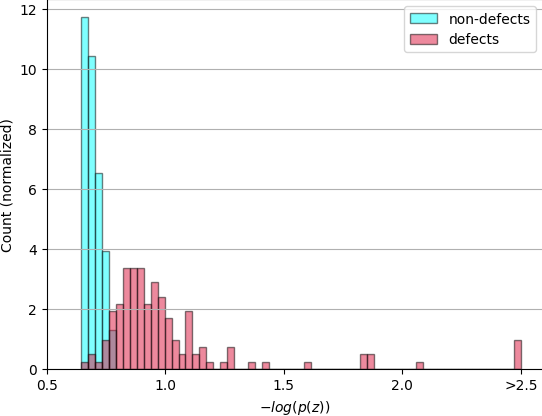

**ROC curve, all defects**

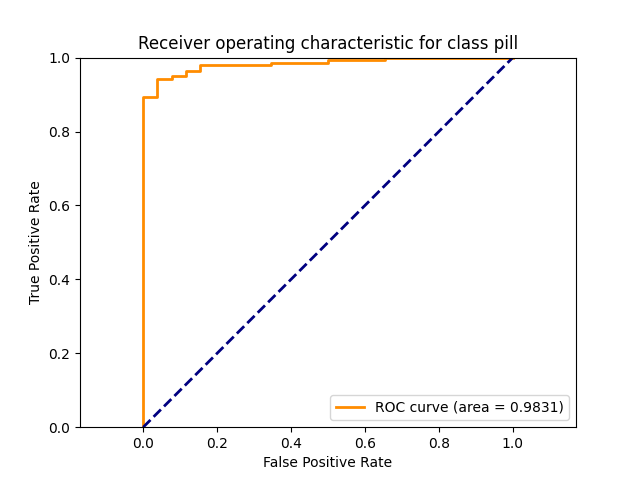

**ROC curve per defect type**

color


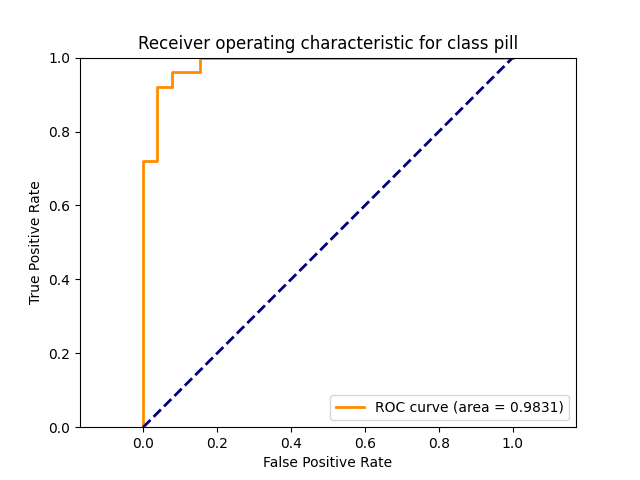

combined


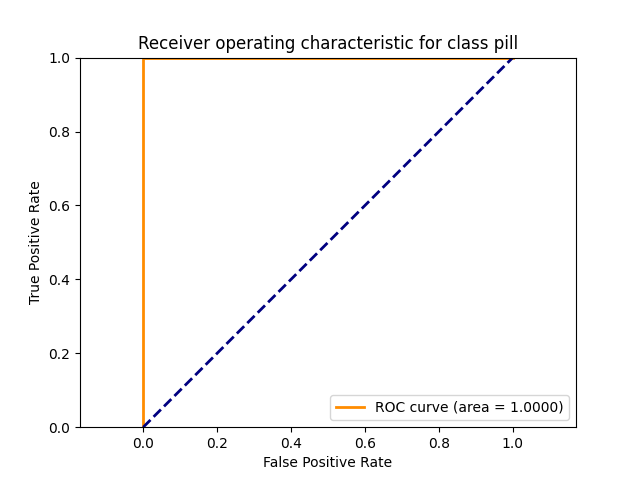

contamination


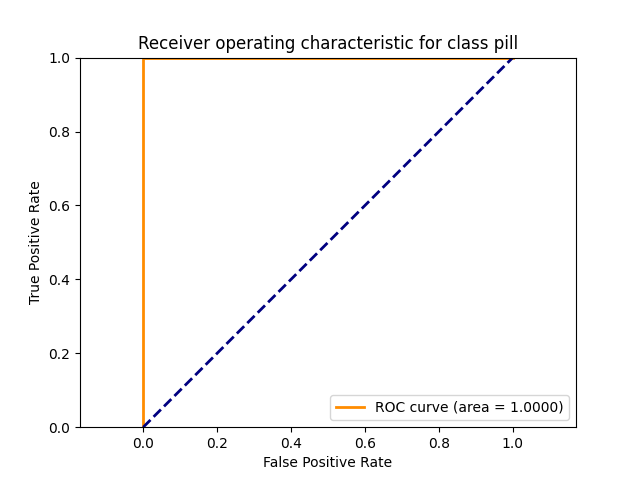

crack


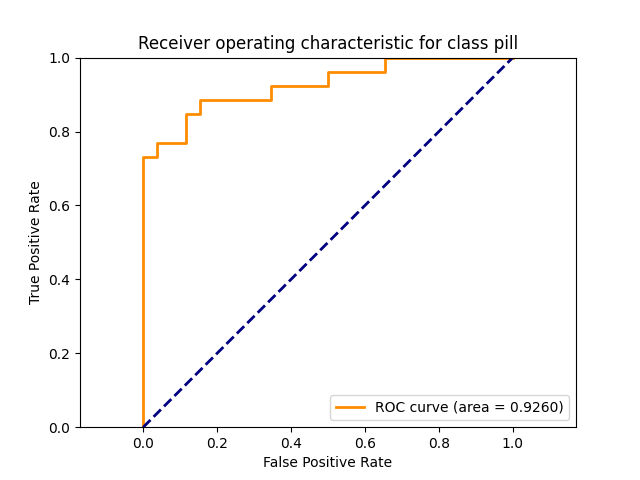

faulty_imprint


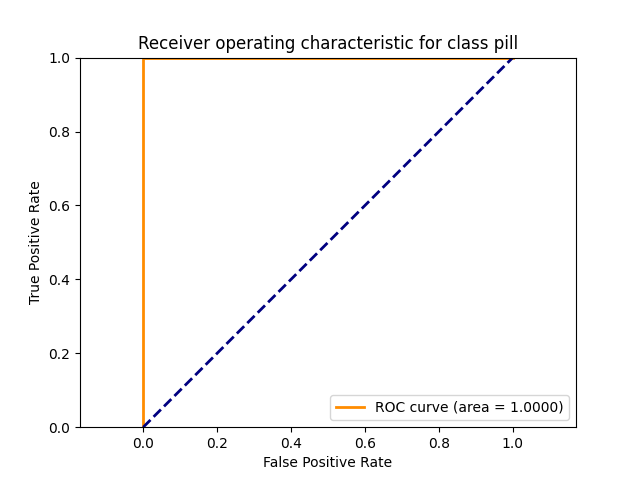

pill_type


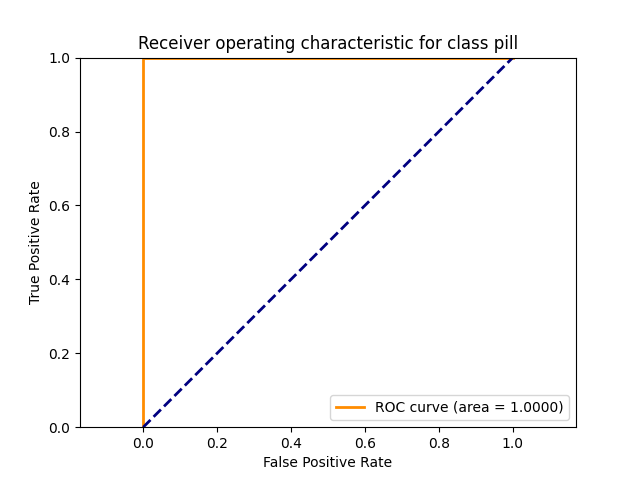

scratch


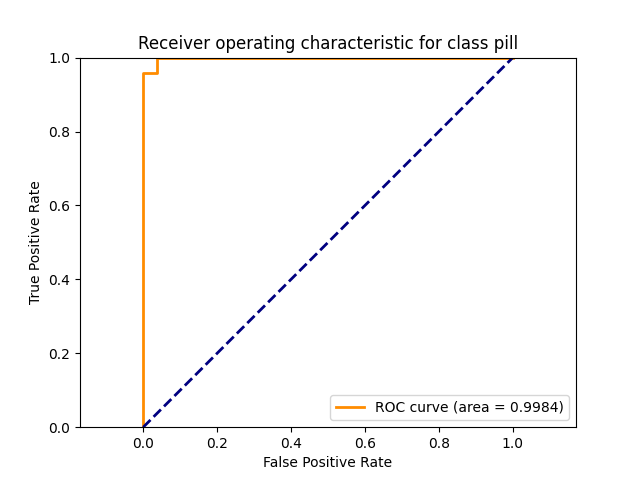

**Anomaly maps** (compare with paper Fig. 7): row 1 image, row 2 map, row 3 overlay.

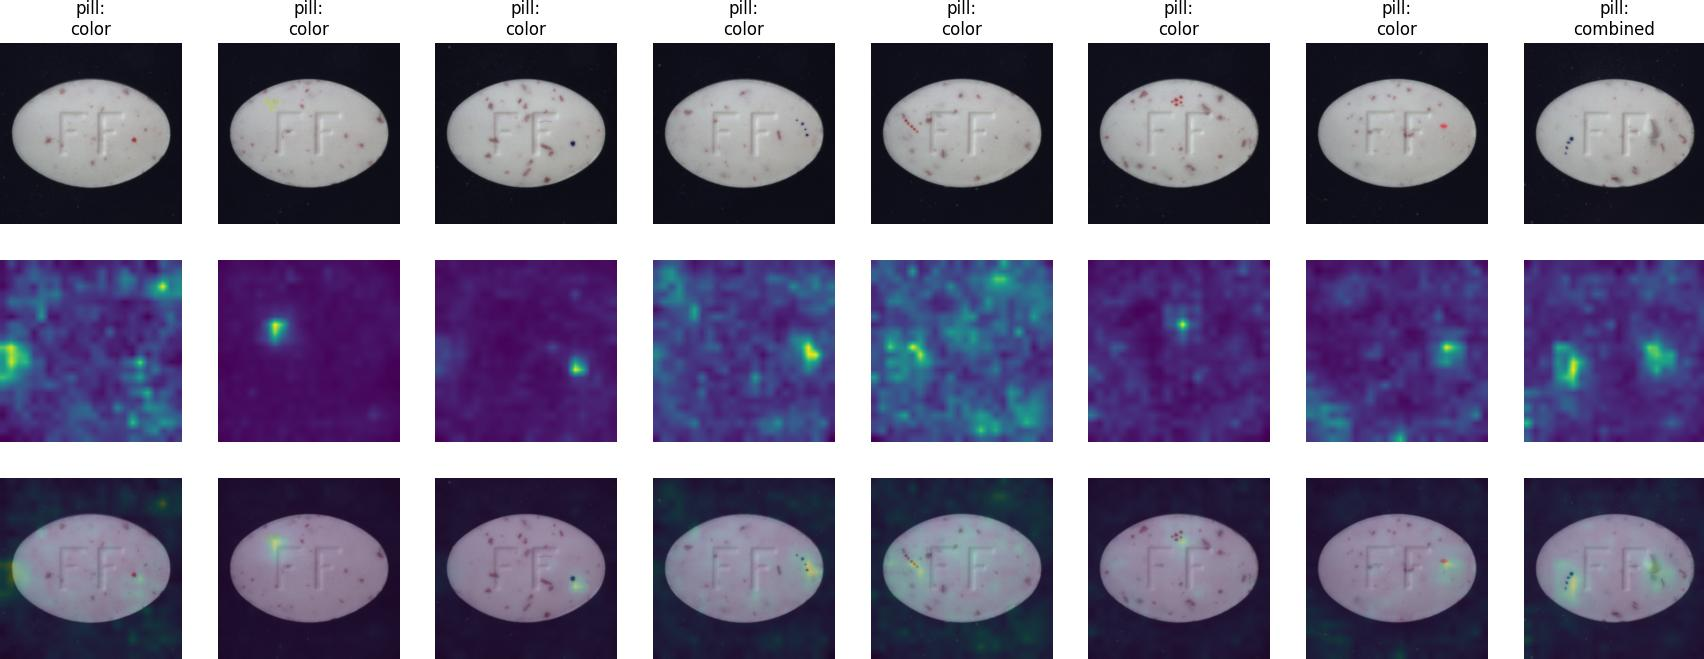

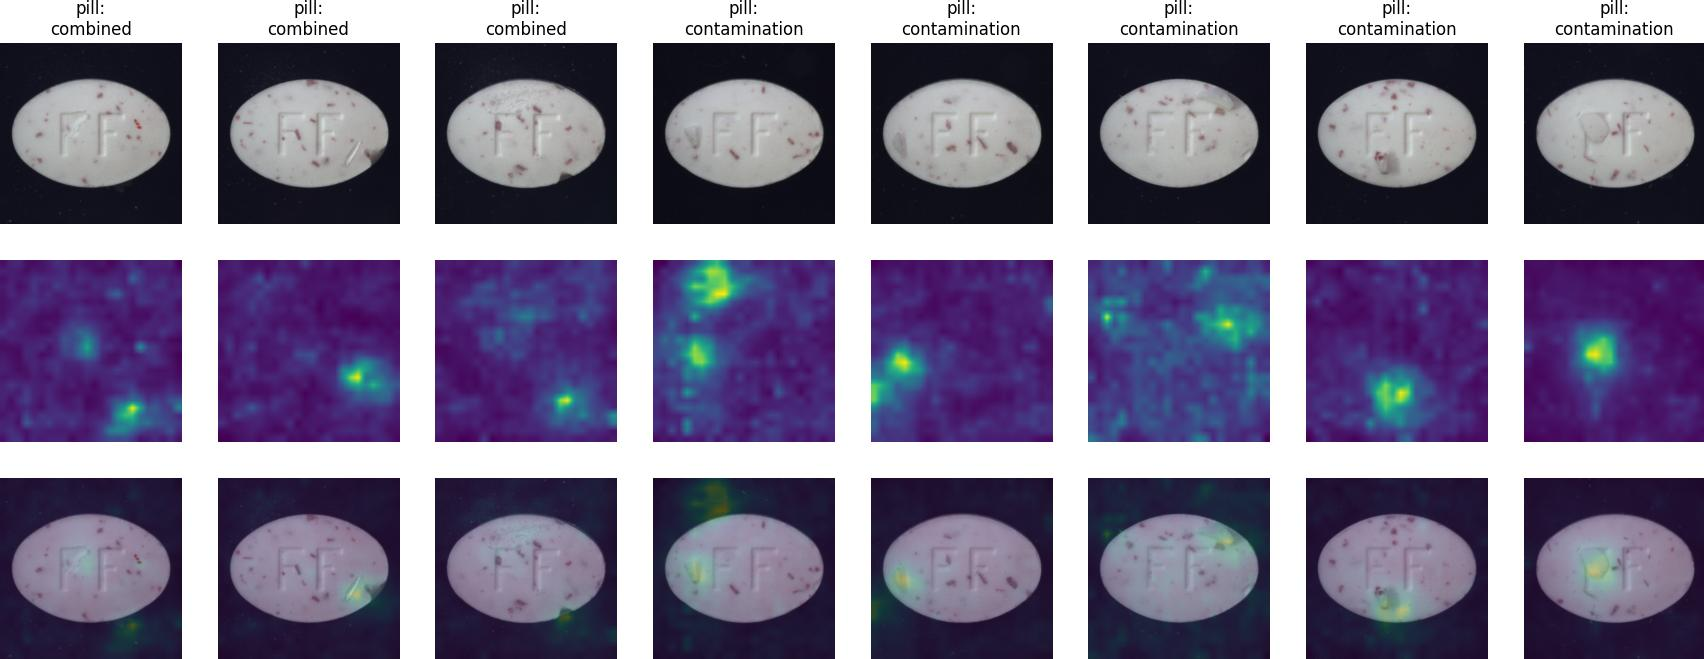

All figures: D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\MVTech Notebook Implementation\viz\scores\mvtec_pill and D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\MVTech Notebook Implementation\viz\maps\mvtec_pill


In [18]:
# 7.2  Show the figures saved by evaluate

score_dir = PROJECT_DIR / 'viz' / 'scores' / c.modelname
map_dir = PROJECT_DIR / 'viz' / 'maps' / c.modelname

display(Markdown('**Anomaly-score histogram** (compare with paper Fig. 5): good images left, defects right.'))
display(Image(filename=str(score_dir / 'score_histogram.png'), width=500))

display(Markdown('**ROC curve, all defects**'))
display(Image(filename=str(score_dir / 'all.png'), width=450))

display(Markdown('**ROC curve per defect type**'))
for png in sorted(score_dir.glob('*.png')):
    if png.name not in ('all.png', 'score_histogram.png'):
        print(png.stem)
        display(Image(filename=str(png), width=350))

display(Markdown('**Anomaly maps** (compare with paper Fig. 7): row 1 image, row 2 map, row 3 overlay.'))
for jpg in sorted(map_dir.glob('*.jpg'), key=lambda p: int(p.stem) if p.stem.isdigit() else 0)[:2]:
    display(Image(filename=str(jpg), width=1000))
print(f'All figures: {score_dir} and {map_dir}')

---
## 8. Results so far vs. the paper



In [19]:
# 8.1  Results table 

results = json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.exists() else {}
print(f'{"class":>11} | {"ours":>6} | {"paper":>6} | {"diff":>6} | epochs | batch | train min')
print('-' * 66)
for cls in sorted(results):
    r = results[cls]
    ours = r['train_final_auroc'] * 100
    paper = PAPER_AUROC.get(cls)
    diff = f'{ours - paper:+6.2f}' if paper is not None else f'{"-":>6}'
    paper_s = f'{paper:6.1f}' if paper is not None else f'{"-":>6}'
    print(f'{cls:>11} | {ours:6.2f} | {paper_s} | {diff} | {r["epochs"]:>6} | {r["batch_size"]:>5} | {r["train_minutes"]:>9}')
print(f'\n{len(results)} of 15 classes done. Not yet trained: '
      + (', '.join(sorted(set(PAPER_AUROC) - set(results))) or 'none'))

      class |   ours |  paper |   diff | epochs | batch | train min
------------------------------------------------------------------
     bottle |  99.76 |   99.8 |  -0.04 |    240 |    16 |      49.2
      cable |  99.21 |   99.1 |  +0.11 |    240 |    16 |      52.0
    capsule |  97.97 |   97.1 |  +0.87 |    240 |    16 |      51.0
     carpet | 100.00 |  100.0 |  +0.00 |    240 |    16 |      65.7
       grid |  97.08 |   99.0 |  -1.92 |    240 |    16 |      61.5
   hazelnut |  99.57 |   99.6 |  -0.03 |    240 |    16 |      91.1
    leather | 100.00 |  100.0 |  +0.00 |    240 |    16 |      57.4
  metal_nut |  97.75 |   99.1 |  -1.35 |    240 |    16 |      51.3
       pill |  98.31 |   98.6 |  -0.29 |    240 |    16 |      62.2
      screw |  96.80 |   97.6 |  -0.80 |    240 |    16 |      74.5
       tile |  99.86 |  100.0 |  -0.14 |    240 |    16 |      53.9
 toothbrush |  93.89 |   91.9 |  +1.99 |    240 |    16 |      14.1
 transistor |  99.46 |   99.3 |  +0.16 |    240 |

In [2]:
import sys
!"{sys.executable}" export_for_sharing.py --model mvtec_tile --class-name tile


copying weights -> share\mvtec_tile\mvtec_tile.pth
Loaded pretrained weights for efficientnet-b5
scoring 117 test images at 768x768 on cuda ...
AUROC with csflow_inference.py: 99.86 %   (notebook evaluation: 99.86 %)
threshold = 0.8539  (99th percentile of 33 good test images)
  good scores    min 0.7578  median 0.7956  max 0.8554
  defect scores  min 0.8442  median 1.9848
  on the test set: 82/84 defects detected, 1/33 good images flagged

Ready to share: D:\learning 2\university\ENTC\5th sem\Image Processing and Machine Vision\Project\New Implementation\MVTech Notebook Implementation\share\mvtec_tile
  csflow_inference.py            0.0 MB
  model_info.json                0.0 MB
  mvtec_tile.pth              1101.0 MB
  README.md                      0.0 MB
  requirements.txt               0.0 MB
  threshold.json                 0.0 MB
